# Why a detector can miss a visible truck

This lesson reads archived **development evidence**. It does not run a neural model, change thresholds, train, acquire data or open a final holdout. The original app remains unchanged. Source: Tampere University / Ultra Video Group, UVG-VCM, Partanen et al. (2026), CC BY 4.0; figures are resized derived overlays.

The clip lasts ten seconds. Repeated observations of the same vehicles are not independent scenes. Student explanations below remain unassessed.

In [1]:
from pathlib import Path
import sys,json,hashlib
ROOT=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents)
           if (p/'src/smart_parking/vision_lesson.py').is_file()
           and (p/'data/manifests/vision_diagnostics_lesson_v1.json').is_file()),None)
if ROOT is None:raise FileNotFoundError('Open this lesson inside the Smart Parking project')
sys.path.insert(0,str(ROOT/'src'))
from smart_parking.vision_lesson import load,CANDIDATE
manifest_path=ROOT/'data/manifests/vision_diagnostics_lesson_v1.json'
assert hashlib.sha256(manifest_path.read_bytes()).hexdigest()=='d5f2af5f9a51f463c8bf97df55f485ea478db2fed6d65250486c3475a188f6c0'
lesson=load(ROOT,json.loads(manifest_path.read_text()))
print('Verified',len(lesson['input_hashes']),'archived development inputs; no model inference or final data.')

Verified 11 archived development inputs; no model inference or final data.


In [2]:
from IPython.display import display,HTML,Image
from html import escape
rows=[]
for name in ['baseline','candidate']:
    run=lesson[name]
    for model,result in run['results'].items():
        eligible=result['eligible_provided']
        rows.append([str(run['detector_resolution']),model,f"{eligible['matched_positives']}/{eligible['provided_positives']}",f"{eligible['recall']:.3f}",str(result['mask_zero_inclusive_mean_iou'])[:7],str(run['all_gates_passed'])])
headers=['Internal side','Model','Eligible matches','Recall','Mask IoU including misses','Absolute gates passed']
display(HTML('<table><tr>'+''.join('<th>'+escape(h)+'</th>' for h in headers)+'</tr>'+''.join('<tr>'+''.join('<td>'+escape(v)+'</td>' for v in row)+'</tr>' for row in rows)+'</table>'))

Internal side,Model,Eligible matches,Recall,Mask IoU including misses,Absolute gates passed
640,fasterrcnn,88/153,0.575,None,False
640,maskrcnn,67/153,0.438,0.34201,False
960,fasterrcnn,102/153,0.667,None,False
960,maskrcnn,87/153,0.569,0.46722,False


The 153 eligible observations have supplied boxes at least 4×4 pixels on the common input. Another 41 smaller car/truck observations remain in separate all-positive results. Train observations are outside the product's road-vehicle scope. These are provided-positive recall values, not exhaustive precision or parking occupancy accuracy.

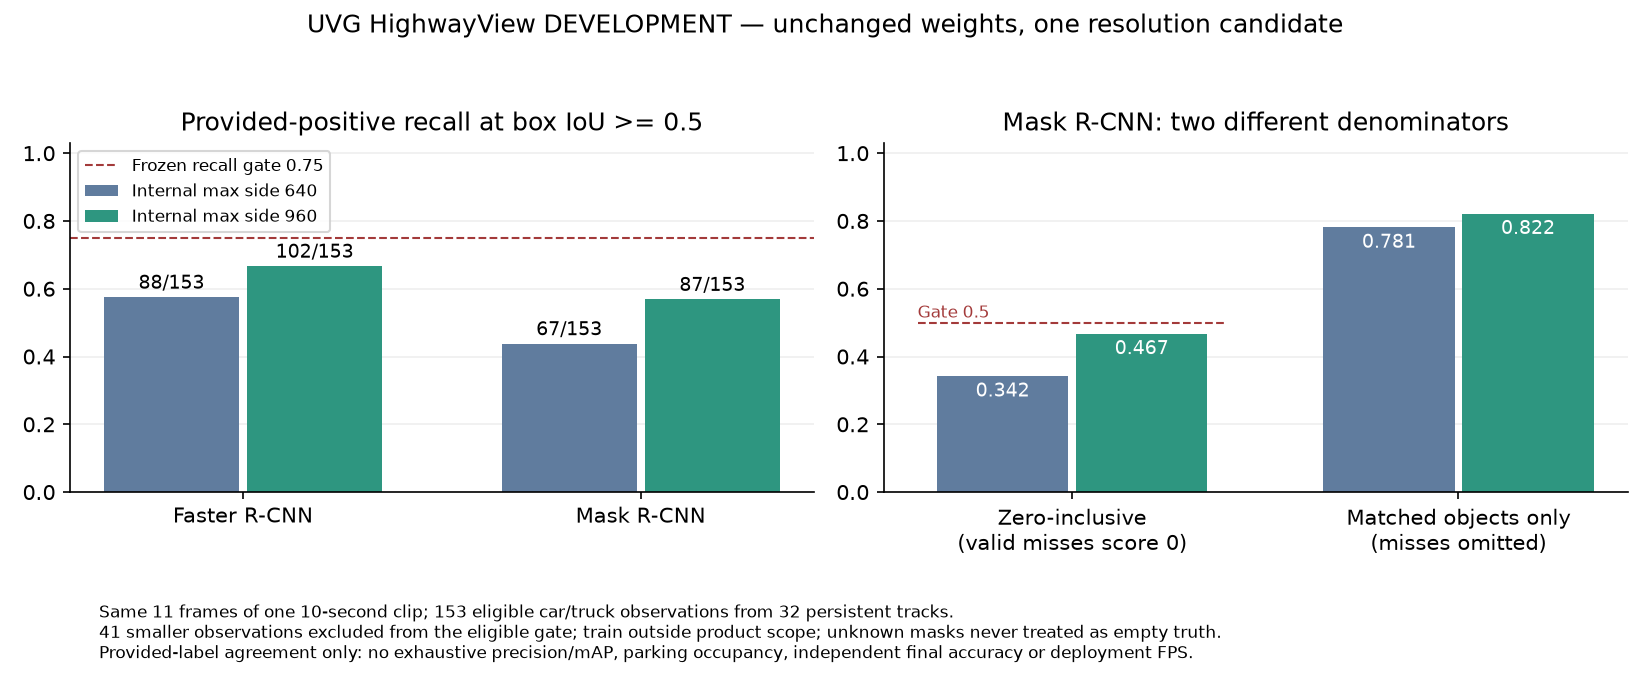

A valid missed target scores zero; an absent truth mask is unknown and excluded. Matched-only IoU omits misses.


In [3]:
display(Image(filename=str(ROOT/f'experiments/results/{CANDIDATE}/development_comparison.png')))
base=lesson['baseline']['results']['maskrcnn'];candidate=lesson['candidate']['results']['maskrcnn']
assert abs(base['mask_zero_inclusive_mean_iou']-0.342017093126219)<1e-12
assert abs(candidate['mask_zero_inclusive_mean_iou']-0.4672242325432266)<1e-12
print('A valid missed target scores zero; an absent truth mask is unknown and excluded. Matched-only IoU omits misses.')

In [4]:
for model,counts in lesson['signatures'].items():
    assert sum(counts.values())==41
    print(model,counts)
truck=lesson['audit']['selected_truck_evidence']
for row in truck:
    evidence=row['best_overlap']
    print(row['model'],'supplied truck; best overlapping output:',evidence['label'],'score',round(evidence['score'],3),'box IoU',round(evidence['iou'],3))
assert next(r for r in truck if r['model']=='maskrcnn')['best_overlap']['label']=='train'
print('These are final post-NMS output signatures, not raw RPN evidence or causal proof.')

fasterrcnn {'matched_at_operating_point': 26, 'same_class_below_operating_threshold': 8, 'unresolved_after_postprocessing': 5, 'same_class_localization_gap': 2}
maskrcnn {'matched_at_operating_point': 24, 'same_class_below_operating_threshold': 2, 'same_class_localization_gap': 1, 'unresolved_after_postprocessing': 13, 'outside_product_class_at_operating_point': 1}
fasterrcnn supplied truck; best overlapping output: truck score 0.813 box IoU 0.964
maskrcnn supplied truck; best overlapping output: train score 0.682 box IoU 0.979
These are final post-NMS output signatures, not raw RPN evidence or causal proof.


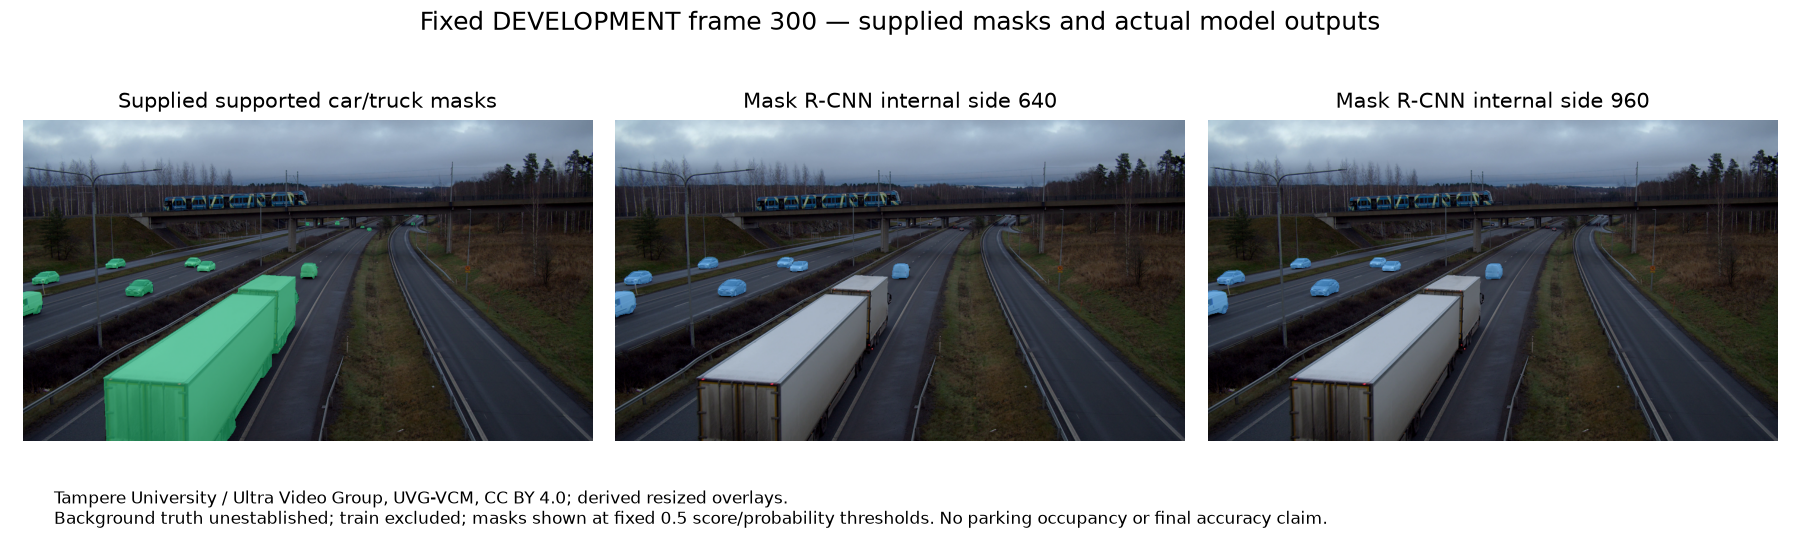

Fixed middle frame 300, not a best-score selection. The actual train on the bridge is outside road-vehicle target scope.


In [5]:
display(Image(filename=str(ROOT/f'experiments/results/{CANDIDATE}/fixed_frame_mask_comparison.png')))
print('Fixed middle frame 300, not a best-score selection. The actual train on the bridge is outside road-vehicle target scope.')

A well-aligned box can have the wrong class. Mask R-CNN called the supplied truck “train”, so the app's road-vehicle filter removed it. Faster R-CNN called this truck correctly. Relabelling every train would create a different error, especially with a real train visible on the bridge. Lowering a threshold also needs appropriate negative evidence; this positive-label study cannot establish exhaustive false-positive safety.

In [6]:
from smart_parking.detection_diagnosis import diagnose
# SYNTHETIC teaching fixture, not a real model prediction or additional experiment.
toy_target=[dict(label='truck',box=[0,0,10,10],track_id=1,eligible=True)]
toy_output=[dict(label='train',score=.8,box=[0,0,10,10])]
toy=diagnose(toy_target,toy_output)
assert toy['rows'][0]['category']=='outside_product_class_at_operating_point'
assert toy['operating_match']['matched_positives']==0
print('Synthetic example:',toy['rows'][0]['category'],'No class remapping is performed.')

Synthetic example: outside_product_class_at_operating_point No class remapping is performed.


In [7]:
checks=dict(archived_inputs=len(lesson['input_hashes']),eligible_per_detector_diagnostic=41,real_source_raw_loaded=lesson['real_source_raw_loaded'],final_result_loaded=lesson['final_result_loaded'],model_inference=lesson['model_inference'],absolute_quality_gates_passed=lesson['candidate']['all_gates_passed'],student_mastery_assessed=False)
assert checks['archived_inputs']==11 and not any(checks[k] for k in ['real_source_raw_loaded','final_result_loaded','model_inference','absolute_quality_gates_passed'])
print('VISION_LESSON_CHECKS='+json.dumps(checks))

VISION_LESSON_CHECKS={"archived_inputs": 11, "eligible_per_detector_diagnostic": 41, "real_source_raw_loaded": false, "final_result_loaded": false, "model_inference": false, "absolute_quality_gates_passed": false, "student_mastery_assessed": false}


## Explain this yourself

1. Why is mask IoU on matched objects stronger than IoU that includes valid misses?
2. Why is an unknown or vanished truth mask excluded rather than labelled empty?
3. Why can a correctly positioned box fail same-class matching?
4. Why do the raw-output audit and higher-resolution study not establish parking occupancy accuracy or justify opening the final sequence?

Independent answers and a real manual presentation are still required. The notebook's successful execution alone does not assess student mastery.